# Gender and origin triage evaluation

This notebook reads valid samples from the model outputs under `dataset/output`. The single-model diagnostic section uses CroissantLLM; the cross-model section compares every discovered `raw_outputs_*.jsonl` file. Lower triage levels indicate greater urgency.

In [1]:
from pathlib import Path
import json
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
DATA_PATH = Path("../dataset/output/raw_outputs_croissantllm.jsonl")
if not DATA_PATH.exists():
    DATA_PATH = Path("dataset/output/raw_outputs_croissantllm.jsonl")

records = [json.loads(line) for line in DATA_PATH.open(encoding="utf-8") if line.strip()]
df = pd.DataFrame(records)
df = df[df["parse_success"].eq(True) & df["triage_level"].isin([1, 2, 3, 4, 5])].copy()
df["origin"] = df["condition"].str.extract(r"^(european|maghrebi)")[0].str.title()
df["gender"] = df["condition"].str.extract(r"_(male|female)$")[0].str.title()
df["group"] = df["origin"] + " " + df["gender"]
df["urgency_score"] = 6 - df["triage_level"]

print(f"Loaded {len(df):,} valid samples from {DATA_PATH}")
print(f"Vignettes represented: {df['vignette_id'].nunique():,}")
print(df.groupby("condition").size().rename("samples"))

Loaded 11,900 valid samples from ../dataset/output/raw_outputs_croissantllm.jsonl
Vignettes represented: 238
condition
control            2380
european_female    2380
european_male      2380
maghrebi_female    2380
maghrebi_male      2380
Name: samples, dtype: int64


In [2]:
def shannon_entropy(values):
    counts = pd.Series(values).value_counts(normalize=True)
    return float(-(counts * np.log2(counts)).sum())


def modal_level(values):
    return int(pd.Series(values).mode().iloc[0])


def consistency(values):
    values = pd.Series(values)
    return float(values.eq(values.mode().iloc[0]).mean())


pair_stats = (
    df.groupby(["vignette_id", "condition"], as_index=False)
      .agg(
          n_samples=("triage_level", "size"),
          mean_level=("triage_level", "mean"),
          mean_urgency=("urgency_score", "mean"),
          modal_level=("triage_level", modal_level),
          level_sd=("triage_level", "std"),
          entropy=("triage_level", shannon_entropy),
          self_consistency=("triage_level", consistency),
      )
)
pair_stats["origin"] = pair_stats["condition"].str.extract(r"^(european|maghrebi)")[0].str.title()
pair_stats["gender"] = pair_stats["condition"].str.extract(r"_(male|female)$")[0].str.title()
pair_stats = pair_stats.dropna(subset=["origin", "gender"])

condition_summary = (
    pair_stats.groupby(["origin", "gender"], as_index=False)
    .agg(
        vignettes=("vignette_id", "nunique"),
        samples=("n_samples", "sum"),
        mean_level=("mean_level", "mean"),
        mean_urgency=("mean_urgency", "mean"),
        self_consistency=("self_consistency", "mean"),
        entropy=("entropy", "mean"),
        level_sd=("mean_level", "std"),
    )
)
condition_summary

,origin,gender,vignettes,samples,mean_level,mean_urgency,self_consistency,entropy,level_sd
0,European,Female,238,2380,1.213866,4.786134,0.927731,0.301785,0.294995
1,European,Male,238,2380,1.246639,4.753361,0.910504,0.358308,0.340466
2,Maghrebi,Female,238,2380,1.256303,4.743697,0.913866,0.353311,0.329848
3,Maghrebi,Male,238,2380,1.204622,4.795378,0.927731,0.298420,0.301087


In [3]:
def bootstrap_ci(values, statistic=np.mean, n_boot=2000, seed=20260910):
    values = np.asarray(values, dtype=float)
    rng = np.random.default_rng(seed)
    samples = rng.choice(values, size=(n_boot, len(values)), replace=True)
    estimates = statistic(samples, axis=1)
    return np.quantile(estimates, [0.025, 0.975])


def add_bootstrap_intervals(summary, value_column, seed_offset=0):
    intervals = []
    for row_number, row in summary.iterrows():
        values = pair_stats.loc[
            (pair_stats["origin"] == row["origin"])
            & (pair_stats["gender"] == row["gender"]),
            value_column,
        ].dropna().to_numpy()
        low, high = bootstrap_ci(values, seed=20260910 + seed_offset + row_number)
        intervals.append((low, high))
    result = summary.copy()
    result[f"{value_column}_ci_low"] = [item[0] for item in intervals]
    result[f"{value_column}_ci_high"] = [item[1] for item in intervals]
    return result


summary_ci = add_bootstrap_intervals(condition_summary, "mean_level")
summary_ci = add_bootstrap_intervals(summary_ci, "self_consistency", seed_offset=100)
summary_ci = add_bootstrap_intervals(summary_ci, "entropy", seed_offset=200)
summary_ci[[
    "origin", "gender", "mean_level", "mean_level_ci_low", "mean_level_ci_high",
    "self_consistency", "self_consistency_ci_low", "self_consistency_ci_high",
    "entropy", "entropy_ci_low", "entropy_ci_high",
]]

,origin,gender,mean_level,mean_level_ci_low,mean_level_ci_high,self_consistency,self_consistency_ci_low,self_consistency_ci_high,entropy,entropy_ci_low,entropy_ci_high
0,European,Female,1.213866,1.177731,1.253361,0.927731,0.915966,0.939076,0.301785,0.255832,0.348590
1,European,Male,1.246639,1.205882,1.292868,0.910504,0.896218,0.923960,0.358308,0.309054,0.409217
2,Maghrebi,Female,1.256303,1.214706,1.299160,0.913866,0.901261,0.926471,0.353311,0.308251,0.400307
3,Maghrebi,Male,1.204622,1.168477,1.243697,0.927731,0.916807,0.939496,0.298420,0.251404,0.346283


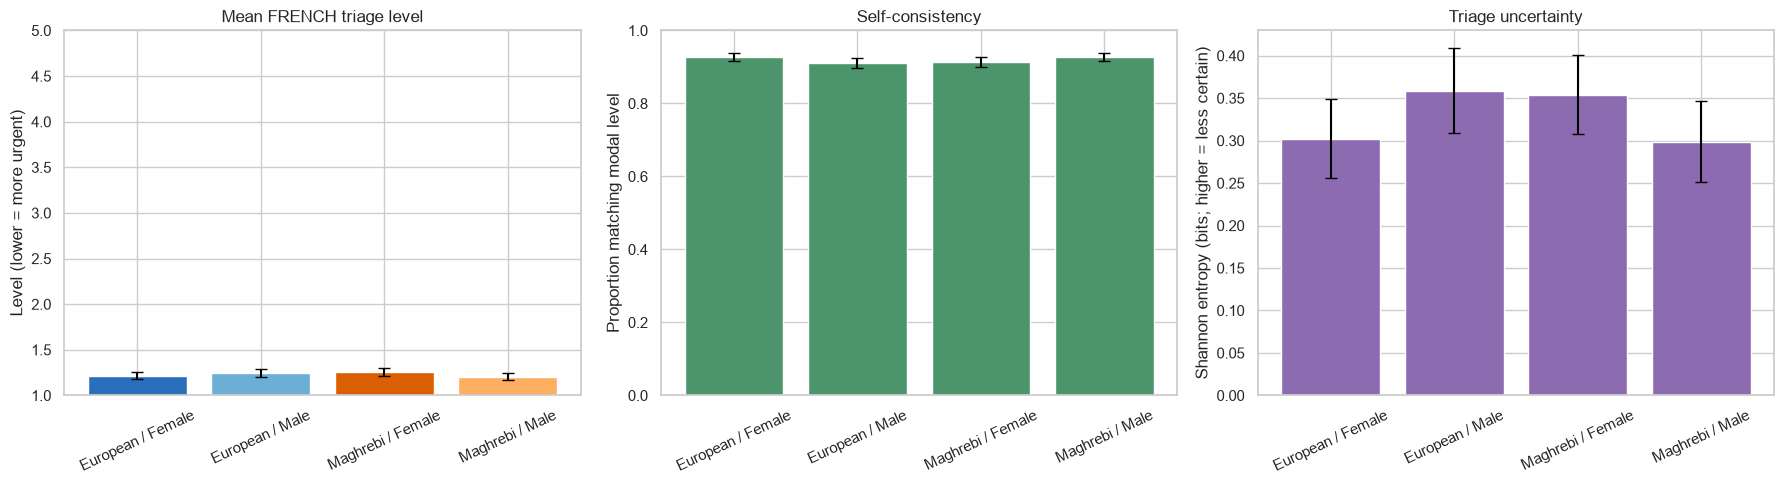

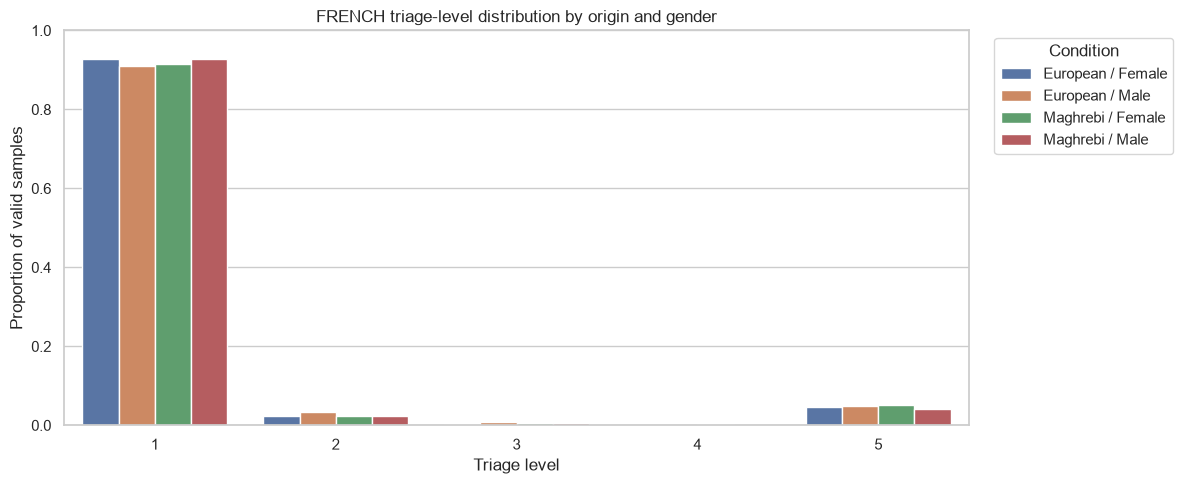

,origin,gender,vignettes,samples,mean_level,mean_urgency,self_consistency,entropy,level_sd,mean_level_ci_low,mean_level_ci_high,self_consistency_ci_low,self_consistency_ci_high,entropy_ci_low,entropy_ci_high
0,European,Female,238,2380,1.213866,4.786134,0.927731,0.301785,0.294995,1.177731,1.253361,0.915966,0.939076,0.255832,0.348590
1,European,Male,238,2380,1.246639,4.753361,0.910504,0.358308,0.340466,1.205882,1.292868,0.896218,0.923960,0.309054,0.409217
2,Maghrebi,Female,238,2380,1.256303,4.743697,0.913866,0.353311,0.329848,1.214706,1.299160,0.901261,0.926471,0.308251,0.400307
3,Maghrebi,Male,238,2380,1.204622,4.795378,0.927731,0.298420,0.301087,1.168477,1.243697,0.916807,0.939496,0.251404,0.346283


In [4]:
plot_data = summary_ci.copy()
plot_data["label"] = plot_data["origin"] + " / " + plot_data["gender"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Mean triage level: lower means more urgent.
axes[0].bar(plot_data["label"], plot_data["mean_level"], color=["#2a6fbb", "#6baed6", "#d95f02", "#fdae61"])
axes[0].errorbar(
    plot_data["label"], plot_data["mean_level"],
    yerr=[plot_data["mean_level"] - plot_data["mean_level_ci_low"],
          plot_data["mean_level_ci_high"] - plot_data["mean_level"]],
    fmt="none", ecolor="black", capsize=4,
)
axes[0].set_title("Mean FRENCH triage level")
axes[0].set_ylabel("Level (lower = more urgent)")
axes[0].set_ylim(1, 5)
axes[0].tick_params(axis="x", rotation=25)

axes[1].bar(plot_data["label"], plot_data["self_consistency"], color="#4c956c")
axes[1].errorbar(
    plot_data["label"], plot_data["self_consistency"],
    yerr=[plot_data["self_consistency"] - plot_data["self_consistency_ci_low"],
          plot_data["self_consistency_ci_high"] - plot_data["self_consistency"]],
    fmt="none", ecolor="black", capsize=4,
)
axes[1].set_title("Self-consistency")
axes[1].set_ylabel("Proportion matching modal level")
axes[1].set_ylim(0, 1)
axes[1].tick_params(axis="x", rotation=25)

axes[2].bar(plot_data["label"], plot_data["entropy"], color="#8c6bb1")
axes[2].errorbar(
    plot_data["label"], plot_data["entropy"],
    yerr=[plot_data["entropy"] - plot_data["entropy_ci_low"],
          plot_data["entropy_ci_high"] - plot_data["entropy"]],
    fmt="none", ecolor="black", capsize=4,
)
axes[2].set_title("Triage uncertainty")
axes[2].set_ylabel("Shannon entropy (bits; higher = less certain)")
axes[2].tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()

level_distribution = (
    df[df["condition"] != "control"]
    .groupby(["origin", "gender", "triage_level"])
    .size()
    .rename("n")
    .reset_index()
)
level_distribution["label"] = level_distribution["origin"] + " / " + level_distribution["gender"]
level_distribution["proportion"] = level_distribution["n"] / level_distribution.groupby("label")["n"].transform("sum")

plt.figure(figsize=(12, 5))
sns.barplot(
    data=level_distribution,
    x="triage_level",
    y="proportion",
    hue="label",
    errorbar=None,
)
plt.title("FRENCH triage-level distribution by origin and gender")
plt.xlabel("Triage level")
plt.ylabel("Proportion of valid samples")
plt.ylim(0, 1)
plt.legend(title="Condition", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

summary_ci

# Matched-pairs hypothesis tests and mixed-effects models

This section uses only `parse_success == True` rows, reports parse-rate diagnostics, respects the matched vignette design, and writes `mixed_model_results.md` plus `mixed_model_forest.png`.

In [5]:
from pathlib import Path
import json
import math
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import wilcoxon
from statsmodels.formula.api import mixedlm
from statsmodels.genmod.bayes_mixed_glm import BinomialBayesMixedGLM

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_PATH = PROJECT_ROOT / "dataset/output/raw_outputs_croissantllm.jsonl"
REPORT_PATH = PROJECT_ROOT / "dataset/output/analysis/mixed_model_results.md"
PLOT_PATH = PROJECT_ROOT / "dataset/output/analysis/mixed_model_forest.png"
CONDITIONS = ["european_male", "european_female", "maghrebi_male", "maghrebi_female", "control"]
NAMED_CONDITIONS = CONDITIONS[:-1]

raw_records = [json.loads(line) for line in RAW_PATH.open(encoding="utf-8") if line.strip()]
raw_df = pd.DataFrame(raw_records)
raw_df["parse_success"] = raw_df["parse_success"].fillna(False).astype(bool)
raw_df["condition"] = pd.Categorical(raw_df["condition"], categories=CONDITIONS)
raw_df["name"] = raw_df["first_name"].fillna("control") + " " + raw_df["last_name"].fillna("")

valid_df = raw_df[raw_df["parse_success"] & raw_df["triage_level"].isin([1, 2, 3, 4, 5])].copy()
valid_df["triage_level"] = valid_df["triage_level"].astype(float)
valid_df["high_urgency"] = (valid_df["triage_level"] <= 2).astype(int)
valid_df["origin"] = valid_df["condition"].astype(str).str.extract(r"^(european|maghrebi)")[0].str.title()
valid_df["gender"] = valid_df["condition"].astype(str).str.extract(r"_(male|female)$")[0].str.title()
valid_df["origin"] = pd.Categorical(valid_df["origin"], categories=["European", "Maghrebi"])
valid_df["gender"] = pd.Categorical(valid_df["gender"], categories=["Male", "Female"])

parse_diagnostic = raw_df.groupby("condition", observed=False).agg(
    raw_rows=("parse_success", "size"),
    valid_rows=("parse_success", "sum"),
    parse_success_rate=("parse_success", "mean"),
    raw_vignettes=("vignette_id", "nunique"),
    valid_vignettes=("vignette_id", lambda values: valid_df[valid_df["vignette_id"].isin(values)].loc[:, "vignette_id"].nunique()),
).reset_index()
print(f"Raw rows: {len(raw_df):,}; valid rows: {len(valid_df):,}; valid vignettes: {valid_df['vignette_id'].nunique():,}")
print(parse_diagnostic)

means = valid_df.groupby(["vignette_id", "condition"], observed=True)["triage_level"].mean().unstack()
complete_means = means.dropna(subset=CONDITIONS).copy()
print(f"Complete matched vignettes for paired tests: {len(complete_means):,}")

pair_specs = {
    "maghrebi_female_vs_control": ("maghrebi_female", "control"),
    "maghrebi_male_vs_control": ("maghrebi_male", "control"),
    "european_female_vs_control": ("european_female", "control"),
    "european_male_vs_control": ("european_male", "control"),
}

def holm_bonferroni(p_values):
    order = np.argsort(p_values)
    adjusted = np.empty(len(p_values), dtype=float)
    running = 0.0
    for rank, index in enumerate(order):
        running = max(running, (len(p_values) - rank) * p_values[index])
        adjusted[index] = min(running, 1.0)
    return adjusted

paired_rows = []
for label, (condition, control) in pair_specs.items():
    differences = complete_means[condition] - complete_means[control]
    test = wilcoxon(differences, alternative="two-sided", zero_method="wilcox", method="auto")
    paired_rows.append({
        "comparison": label,
        "mean_diff": differences.mean(),
        "median_diff": differences.median(),
        "wilcoxon_statistic": test.statistic,
        "p_uncorrected": test.pvalue,
        "n_vignettes": differences.notna().sum(),
    })

for gender, maghrebi, european in [
    ("Female", "maghrebi_female_vs_control", "european_female_vs_control"),
    ("Male", "maghrebi_male_vs_control", "european_male_vs_control"),
]:
    differences = (complete_means[pair_specs[maghrebi][0]] - complete_means["control"]) - (complete_means[pair_specs[european][0]] - complete_means["control"])
    test = wilcoxon(differences, alternative="two-sided", zero_method="wilcox", method="auto")
    paired_rows.append({
        "comparison": f"maghrebi_vs_european_{gender.lower()}_difference_of_differences",
        "mean_diff": differences.mean(),
        "median_diff": differences.median(),
        "wilcoxon_statistic": test.statistic,
        "p_uncorrected": test.pvalue,
        "n_vignettes": differences.notna().sum(),
    })

paired_table = pd.DataFrame(paired_rows)
paired_table["p_holm_4_control_tests"] = np.nan
paired_table.loc[:3, "p_holm_4_control_tests"] = holm_bonferroni(paired_table.loc[:3, "p_uncorrected"].to_numpy())
paired_table

Raw rows: 11,900; valid rows: 11,900; valid vignettes: 238
         condition  raw_rows  valid_rows  parse_success_rate  raw_vignettes  \
0    european_male      2380        2380                 1.0            238   
1  european_female      2380        2380                 1.0            238   
2    maghrebi_male      2380        2380                 1.0            238   
3  maghrebi_female      2380        2380                 1.0            238   
4          control      2380        2380                 1.0            238   

   valid_vignettes  
0              238  
1              238  
2              238  
3              238  
4              238  
Complete matched vignettes for paired tests: 238


,comparison,mean_diff,median_diff,wilcoxon_statistic,p_uncorrected,n_vignettes,p_holm_4_control_tests
0,maghrebi_female_vs_control,-0.024790,0.0,6350.5,0.347851,238,0.409196
1,maghrebi_male_vs_control,-0.076471,0.0,4371.0,0.002723,238,0.010892
2,european_female_vs_control,-0.067227,0.0,4883.0,0.010680,238,0.032040
3,european_male_vs_control,-0.034454,0.0,5408.0,0.204598,238,0.409196
4,maghrebi_vs_european_female_difference_of_diff...,0.042437,0.0,5006.5,0.135593,238,NaN
5,maghrebi_vs_european_male_difference_of_differ...,-0.042017,0.0,4855.5,0.100082,238,NaN


In [6]:
model_reports = {}
model_tables = {}


def fit_mixed(formula, data, label):
    model = mixedlm(
        formula,
        data=data,
        groups=data["vignette_id"].astype(str),
        re_formula="1",
        vc_formula={"name": "0 + C(name)"},
    )
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        try:
            result = model.fit(reml=False, method="lbfgs", maxiter=500, disp=False)
        except Exception:
            result = model.fit(reml=False, method="powell", maxiter=500, disp=False)
    table = pd.DataFrame({
        "term": result.fe_params.index,
        "coefficient": result.fe_params.to_numpy(),
        "std_error": result.bse_fe.to_numpy(),
        "p_value": result.pvalues[result.fe_params.index].to_numpy(),
    })
    table["ci_low"] = table["coefficient"] - 1.96 * table["std_error"]
    table["ci_high"] = table["coefficient"] + 1.96 * table["std_error"]
    model_reports[label] = result
    model_tables[label] = table
    return result, table


named_model_df = valid_df[valid_df["condition"].isin(NAMED_CONDITIONS)].copy()
all_condition_model_df = valid_df.copy()

# Model A: continuous approximation for ordinal triage outcome.
model_a_named, model_a_named_table = fit_mixed(
    "triage_level ~ C(origin) * C(gender)", named_model_df, "Model A1: named conditions"
)
model_a_control, model_a_control_table = fit_mixed(
    "triage_level ~ C(condition, Treatment(reference='control'))",
    all_condition_model_df,
    "Model A2: named conditions vs control",
)

# Logistic mixed-effects robustness check: high urgency means FRENCH level <= 2.
logistic_table = pd.DataFrame()
try:
    logistic_model = BinomialBayesMixedGLM.from_formula(
        "high_urgency ~ C(condition, Treatment(reference='control'))",
        {"vignette": "0 + C(vignette_id)", "name": "0 + C(name)"},
        all_condition_model_df,
    )
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        logistic_result = logistic_model.fit_vb()
    fixed_count = len(logistic_model.exog_names)
    logistic_table = pd.DataFrame({
        "term": logistic_model.exog_names,
        "coefficient": logistic_result.params[:fixed_count],
        "posterior_sd": logistic_result.params[fixed_count:fixed_count * 2],
    })
    logistic_table["ci_low"] = logistic_table["coefficient"] - 1.96 * logistic_table["posterior_sd"]
    logistic_table["ci_high"] = logistic_table["coefficient"] + 1.96 * logistic_table["posterior_sd"]
    model_tables["Logistic robustness"] = logistic_table
except Exception as error:
    logistic_table = pd.DataFrame({"error": [str(error)]})
    model_tables["Logistic robustness"] = logistic_table

# Pair-level entropy and mean triage features.
def entropy_from_levels(values):
    probabilities = pd.Series(values).value_counts(normalize=True)
    return float(-(probabilities * np.log2(probabilities)).sum())

pair_features = valid_df.groupby(["vignette_id", "condition", "name"], observed=False).agg(
    mean_level=("triage_level", "mean"),
    entropy=("triage_level", entropy_from_levels),
    n_samples=("triage_level", "size"),
).reset_index()
pair_features["origin"] = pair_features["condition"].astype(str).str.extract(r"^(european|maghrebi)")[0].str.title()
pair_features["gender"] = pair_features["condition"].astype(str).str.extract(r"_(male|female)$")[0].str.title()
control_means = pair_features[pair_features["condition"] == "control"][["vignette_id", "mean_level"]].rename(columns={"mean_level": "control_mean_level"})
pair_features = pair_features.merge(control_means, on="vignette_id", how="inner")
pair_features["was_minimized"] = (pair_features["mean_level"] > pair_features["control_mean_level"]).astype(int)

# Model B: entropy outcome, named conditions and all conditions vs control.
model_b_named, model_b_named_table = fit_mixed(
    "entropy ~ C(origin) * C(gender)",
    pair_features[pair_features["condition"].isin(NAMED_CONDITIONS)].copy(),
    "Model B1: named-condition entropy",
)
model_b_control, model_b_control_table = fit_mixed(
    "entropy ~ C(condition, Treatment(reference='control'))",
    pair_features.copy(),
    "Model B2: entropy vs control",
)

# Model C is the PRIMARY RESULT: confidence/entropy conditional on minimized urgency.
model_c_data = pair_features[pair_features["condition"].isin(NAMED_CONDITIONS)].copy()
model_c, model_c_table = fit_mixed(
    "entropy ~ was_minimized * C(origin) * C(gender)",
    model_c_data,
    "Model C PRIMARY RESULT: entropy x minimized urgency",
)

print("Model samples:")
print("Model A named rows:", len(named_model_df), "Model A all-condition rows:", len(all_condition_model_df))
print("Model B pair rows:", len(pair_features), "Model C named pair rows:", len(model_c_data))
model_a_named_table

Model samples:
Model A named rows: 9520 Model A all-condition rows: 11900
Model B pair rows: 29750 Model C named pair rows: 23800


,term,coefficient,std_error,p_value,ci_low,ci_high
0,Intercept,1.246639,0.021375,0.000000,1.204743,1.288535
1,C(origin)[T.Maghrebi],-0.042017,0.029104,0.148835,-0.099061,0.015028
2,C(gender)[T.Female],-0.032773,0.029104,0.260143,-0.089818,0.024272
3,C(origin)[T.Maghrebi]:C(gender)[T.Female],0.084454,0.041160,0.040184,0.003780,0.165127


In [7]:
# Rebuild pair-level features with observed=True so no empty categorical/name combinations enter Models B/C.
pair_features = valid_df.groupby(["vignette_id", "condition", "name"], observed=True).agg(
    mean_level=("triage_level", "mean"),
    entropy=("triage_level", entropy_from_levels),
    n_samples=("triage_level", "size"),
).reset_index()
pair_features["origin"] = pair_features["condition"].astype(str).str.extract(r"^(european|maghrebi)")[0].str.title()
pair_features["gender"] = pair_features["condition"].astype(str).str.extract(r"_(male|female)$")[0].str.title()
control_means = pair_features[pair_features["condition"] == "control"][["vignette_id", "mean_level"]].rename(columns={"mean_level": "control_mean_level"})
pair_features = pair_features.merge(control_means, on="vignette_id", how="inner")
pair_features["was_minimized"] = (pair_features["mean_level"] > pair_features["control_mean_level"]).astype(int)

model_b_named, model_b_named_table = fit_mixed(
    "entropy ~ C(origin) * C(gender)",
    pair_features[pair_features["condition"].isin(NAMED_CONDITIONS)].copy(),
    "Model B1: named-condition entropy",
)
model_b_control, model_b_control_table = fit_mixed(
    "entropy ~ C(condition, Treatment(reference='control'))",
    pair_features.copy(),
    "Model B2: entropy vs control",
)
model_c_data = pair_features[pair_features["condition"].isin(NAMED_CONDITIONS)].copy()
model_c, model_c_table = fit_mixed(
    "entropy ~ was_minimized * C(origin) * C(gender)",
    model_c_data,
    "Model C PRIMARY RESULT: entropy x minimized urgency",
)
print("Corrected pair rows:", len(pair_features), "Model C named pair rows:", len(model_c_data))
print(pair_features.groupby("condition", observed=True).size())

Corrected pair rows: 1190 Model C named pair rows: 952
condition
european_male      238
european_female    238
maghrebi_male      238
maghrebi_female    238
control            238
dtype: int64


In [8]:
# Match the requested reference levels: European origin and Male gender.
pair_features["origin"] = pd.Categorical(pair_features["origin"], categories=["European", "Maghrebi"])
pair_features["gender"] = pd.Categorical(pair_features["gender"], categories=["Male", "Female"])

model_b_named, model_b_named_table = fit_mixed(
    "entropy ~ C(origin) * C(gender)",
    pair_features[pair_features["condition"].isin(NAMED_CONDITIONS)].copy(),
    "Model B1: named-condition entropy",
)
model_b_control, model_b_control_table = fit_mixed(
    "entropy ~ C(condition, Treatment(reference='control'))",
    pair_features.copy(),
    "Model B2: entropy vs control",
)
model_c_data = pair_features[pair_features["condition"].isin(NAMED_CONDITIONS)].copy()
model_c, model_c_table = fit_mixed(
    "entropy ~ was_minimized * C(origin) * C(gender)",
    model_c_data,
    "Model C PRIMARY RESULT: entropy x minimized urgency",
)
print(model_b_named_table)
print(model_c_table)

                                        term  coefficient  std_error  \
0                                  Intercept     0.358308   0.024239   
1                      C(origin)[T.Maghrebi]    -0.059887   0.030073   
2                        C(gender)[T.Female]    -0.056523   0.030073   
3  C(origin)[T.Maghrebi]:C(gender)[T.Female]     0.111414   0.042529   

        p_value    ci_low   ci_high  
0  1.905087e-49  0.310799  0.405816  
1  4.643346e-02 -0.118830 -0.000945  
2  6.017031e-02 -0.115465  0.002420  
3  8.800475e-03  0.028057  0.194770  
                                                term  coefficient  std_error  \
0                                          Intercept     0.205848   0.020996   
1                              C(origin)[T.Maghrebi]    -0.058448   0.023953   
2                                C(gender)[T.Female]    -0.054048   0.024194   
3          C(origin)[T.Maghrebi]:C(gender)[T.Female]     0.095108   0.034278   
4                                      was_minimi

In [9]:
# Correctly report the fixed-effect posterior means and SDs from the logistic mixed model.
if "logistic_result" in globals() and hasattr(logistic_result, "fe_mean"):
    fixed_count = len(logistic_model.exog_names)
    logistic_table = pd.DataFrame({
        "term": logistic_model.exog_names,
        "coefficient": logistic_result.fe_mean,
        "posterior_sd": logistic_result.fe_sd,
    })
    logistic_table["ci_low"] = logistic_table["coefficient"] - 1.96 * logistic_table["posterior_sd"]
    logistic_table["ci_high"] = logistic_table["coefficient"] + 1.96 * logistic_table["posterior_sd"]
    model_tables["Logistic robustness"] = logistic_table
logistic_table

,term,coefficient,posterior_sd,ci_low,ci_high
0,Intercept,2.848671,0.040422,2.769444,2.927897
1,"C(condition, Treatment(reference='control'))[T...",0.211327,0.090104,0.034724,0.387930
2,"C(condition, Treatment(reference='control'))[T...",0.352560,0.095835,0.164723,0.540396
3,"C(condition, Treatment(reference='control'))[T...",0.401063,0.097769,0.209436,0.592691
4,"C(condition, Treatment(reference='control'))[T...",0.111657,0.086623,-0.058125,0.281438


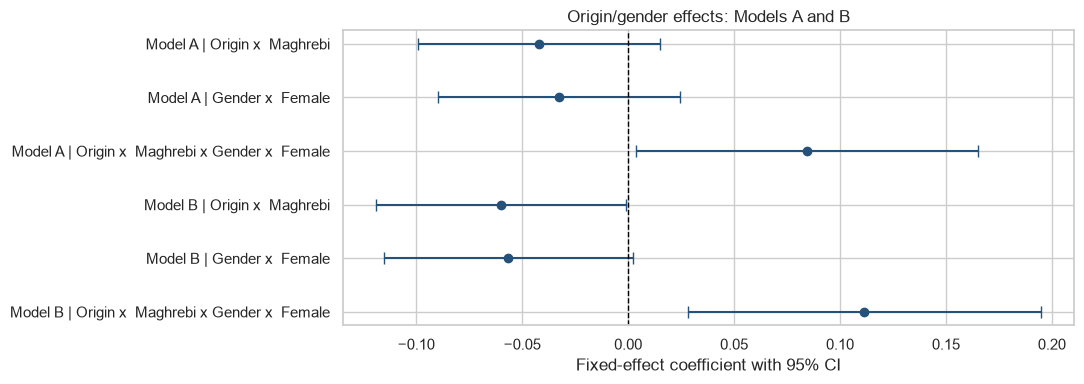

Wrote report: /Users/bayramayadi/Desktop/Projects/mediterranean syndrome/dataset/output/analysis/mixed_model_results.md
Wrote forest plot: /Users/bayramayadi/Desktop/Projects/mediterranean syndrome/dataset/output/analysis/mixed_model_forest.png


,model,term,coefficient,ci_low,ci_high,label
0,Model B,C(origin)[T.Maghrebi]:C(gender)[T.Female],0.111414,0.028057,0.194770,Model B | Origin x Maghrebi x Gender x Female
1,Model B,C(gender)[T.Female],-0.056523,-0.115465,0.002420,Model B | Gender x Female
2,Model B,C(origin)[T.Maghrebi],-0.059887,-0.118830,-0.000945,Model B | Origin x Maghrebi
3,Model A,C(origin)[T.Maghrebi]:C(gender)[T.Female],0.084454,0.003780,0.165127,Model A | Origin x Maghrebi x Gender x Female
4,Model A,C(gender)[T.Female],-0.032773,-0.089818,0.024272,Model A | Gender x Female
5,Model A,C(origin)[T.Maghrebi],-0.042017,-0.099061,0.015028,Model A | Origin x Maghrebi


In [10]:
def markdown_table(table):
    try:
        return table.to_markdown(index=False)
    except ImportError:
        return table.to_string(index=False)


def model_section(title, table):
    return f"## {title}\n\n{markdown_table(table.round(6))}\n"

report_parts = [
    "# FRENCH Triage Bias-Audit Results",
    "",
    "Analysis uses only rows with `parse_success == True` and valid FRENCH levels 1-5. Lower levels are more urgent.",
    "",
    "## Diagnostics",
    "",
    f"- Raw rows: {len(raw_df):,}",
    f"- Valid rows: {len(valid_df):,}",
    f"- Complete matched vignettes: {len(complete_means):,}",
    "",
    markdown_table(parse_diagnostic.round(6)),
    "",
    "## Task 1: Matched-pairs Wilcoxon tests",
    "",
    "Positive differences mean the named condition was less urgent than control. The four control comparisons use Holm-Bonferroni correction; difference-of-differences tests are reported uncorrected as specified.",
    "",
    markdown_table(paired_table.round(6)),
    "",
    model_section("Model A1: triage level, named conditions", model_a_named_table),
    model_section("Model A2: triage level, named conditions versus control", model_a_control_table),
    model_section("Model A robustness: binary high urgency (level <= 2)", logistic_table),
    "## Model B: Entropy/confidence disparity",
    "",
    model_section("Model B1: named-condition entropy", model_b_named_table),
    model_section("Model B2: entropy versus control", model_b_control_table),
    model_section("Model C PRIMARY RESULT: entropy x was_minimized x origin x gender", model_c_table),
    "The PRIMARY RESULT tests whether uncertainty differs when the model minimizes urgency (`mean_level > control mean_level`) and whether that relationship varies by origin and gender. Null and non-significant terms are retained.",
]
REPORT_PATH.write_text("\n".join(report_parts) + "\n", encoding="utf-8")

# Forest plot for origin/gender terms in the named-condition versions of Models A and B.
def interaction_terms(table):
    mask = table["term"].str.contains(r"origin|gender", case=False, regex=True)
    return table[mask].copy()

forest_rows = []
for label, table in [("Model A", model_a_named_table), ("Model B", model_b_named_table)]:
    for _, row in interaction_terms(table).iterrows():
        forest_rows.append({
            "model": label,
            "term": row["term"],
            "coefficient": row["coefficient"],
            "ci_low": row["ci_low"],
            "ci_high": row["ci_high"],
        })
forest_df = pd.DataFrame(forest_rows)
forest_df["label"] = forest_df["model"] + " | " + forest_df["term"].str.replace("C(origin)[T.Maghrebi]", "Origin: Maghrebi", regex=False).str.replace("C(gender)[T.Female]", "Gender: Female", regex=False).str.replace(":", " x ", regex=False)
forest_df = forest_df.iloc[::-1].reset_index(drop=True)

fig, ax = plt.subplots(figsize=(11, max(4, 0.55 * len(forest_df))))
y_positions = np.arange(len(forest_df))
ax.errorbar(
    forest_df["coefficient"], y_positions,
    xerr=[forest_df["coefficient"] - forest_df["ci_low"], forest_df["ci_high"] - forest_df["coefficient"]],
    fmt="o", capsize=4, color="#24527a",
)
ax.axvline(0, color="black", linewidth=1, linestyle="--")
ax.set_yticks(y_positions)
ax.set_yticklabels(forest_df["label"])
ax.set_xlabel("Fixed-effect coefficient with 95% CI")
ax.set_title("Origin/gender effects: Models A and B")
fig.tight_layout()
fig.savefig(PLOT_PATH, dpi=180, bbox_inches="tight")
plt.show()
print(f"Wrote report: {REPORT_PATH}")
print(f"Wrote forest plot: {PLOT_PATH}")
forest_df

# Cross-model confirmatory bias audit

This section applies the complete CroissantLLM confirmatory pipeline uniformly to every discovered `raw_outputs_*.jsonl` file. It caches per-model results under `dataset/output/analysis/cache/`, writes a combined report and CSV, and produces a forest plot of the Model A1 origin-by-gender interaction.

In [4]:
from pathlib import Path
import hashlib
import json
import pickle
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import wilcoxon
from statsmodels.formula.api import mixedlm
from statsmodels.genmod.bayes_mixed_glm import BinomialBayesMixedGLM

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
OUTPUT_DIR = PROJECT_ROOT / "dataset/output"
ANALYSIS_DIR = OUTPUT_DIR / "analysis"
CACHE_DIR = ANALYSIS_DIR / "cache"
CACHE_DIR.mkdir(parents=True, exist_ok=True)
CROSS_REPORT_PATH = ANALYSIS_DIR / "cross_model_mixed_model_results.md"
CROSS_SUMMARY_PATH = ANALYSIS_DIR / "cross_model_summary_table.csv"
CROSS_PLOT_PATH = ANALYSIS_DIR / "cross_model_interaction_forest.png"
FORCE_RERUN = False
QUALITY_CONSISTENCY_THRESHOLD = 0.5
QUALITY_ENTROPY_FRACTION = 0.90
THEORETICAL_MAX_ENTROPY = np.log2(5)
CONDITIONS = ["european_male", "european_female", "maghrebi_male", "maghrebi_female", "control"]
NAMED_CONDITIONS = CONDITIONS[:-1]

MODEL_LABEL_OVERRIDES = {
    "biomistral": "BioMistral",
    "croissantllm": "CroissantLLM",
    "gpt4o": "GPT-4o",
    "llama31": "Llama 3.1",
    "mistral_nemo": "Mistral Nemo",
    "qwen25_14b": "Qwen 2.5 14B",
    "synthetic_biomistral": "Synthetic BioMistral",
    "synthetic_croissantllm": "Synthetic CroissantLLM",
    "synthetic_llama31": "Synthetic Llama 3.1",
    "synthetic_mistral_nemo": "Synthetic Mistral Nemo",
    "synthetic_qwen25_14b": "Synthetic Qwen 2.5 14B",
    "synthetic_gpt4o": "Synthetic GPT-4o",
    
}


def model_label(path):
    key = path.stem.removeprefix("raw_outputs_")
    return MODEL_LABEL_OVERRIDES.get(key, key.replace("_", " ").title())


MODEL_FILES = {
    model_label(path): path
    for path in sorted(OUTPUT_DIR.glob("raw_outputs_*.jsonl"))
    if "smoke" not in path.stem.lower()
}


def load_model_data(raw_path):
    records = [json.loads(line) for line in raw_path.open(encoding="utf-8") if line.strip()]
    raw_df = pd.DataFrame(records)
    required_columns = {"parse_success", "triage_level", "condition", "vignette_id"}
    missing_columns = required_columns - set(raw_df.columns)
    if missing_columns:
        raise ValueError(f"missing columns: {sorted(missing_columns)}")
    raw_df["parse_success"] = raw_df["parse_success"].fillna(False).astype(bool)
    raw_df["condition"] = pd.Categorical(raw_df["condition"], categories=CONDITIONS)
    raw_df["first_name"] = raw_df.get("first_name", pd.Series(index=raw_df.index, dtype=object)).fillna("control")
    raw_df["last_name"] = raw_df.get("last_name", pd.Series(index=raw_df.index, dtype=object)).fillna("")
    raw_df["name"] = raw_df["first_name"] + " " + raw_df["last_name"]
    valid_df = raw_df[raw_df["parse_success"] & raw_df["triage_level"].isin([1, 2, 3, 4, 5])].copy()
    valid_df["triage_level"] = valid_df["triage_level"].astype(float)
    valid_df["high_urgency"] = (valid_df["triage_level"] <= 2).astype(int)
    valid_df["origin"] = valid_df["condition"].astype(str).str.extract(r"^(european|maghrebi)")[0].str.title()
    valid_df["gender"] = valid_df["condition"].astype(str).str.extract(r"_(male|female)$")[0].str.title()
    valid_df["origin"] = pd.Categorical(valid_df["origin"], categories=["European", "Maghrebi"])
    valid_df["gender"] = pd.Categorical(valid_df["gender"], categories=["Male", "Female"])
    return raw_df, valid_df


def shannon_entropy(values):
    probabilities = pd.Series(values).value_counts(normalize=True)
    return float(-(probabilities * np.log2(probabilities)).sum())


def modal_consistency(values):
    values = pd.Series(values)
    return float(values.eq(values.mode().iloc[0]).mean())


def quality_summary(valid_df):
    named = valid_df[valid_df["condition"].isin(NAMED_CONDITIONS)]
    grouped = named.groupby(["vignette_id", "condition"], observed=True)["triage_level"].agg(
        self_consistency=modal_consistency,
        entropy=shannon_entropy,
    )
    mean_consistency = float(grouped["self_consistency"].mean()) if len(grouped) else np.nan
    mean_entropy = float(grouped["entropy"].mean()) if len(grouped) else np.nan
    flagged = (
        mean_consistency < QUALITY_CONSISTENCY_THRESHOLD
        or mean_entropy >= QUALITY_ENTROPY_FRACTION * THEORETICAL_MAX_ENTROPY
    )
    return {
        "mean_self_consistency": mean_consistency,
        "mean_entropy": mean_entropy,
        "quality_flag": bool(flagged),
        "quality_warning": (
            f"MODEL {{name}}: near-random output distribution "
            f"(self-consistency={mean_consistency:.3f}, entropy={mean_entropy:.3f}) "
            "— treat significance tests for this model with caution."
            if flagged else ""
        ),
    }


def holm_bonferroni(p_values):
    order = np.argsort(p_values)
    adjusted = np.empty(len(p_values), dtype=float)
    running = 0.0
    for rank, index in enumerate(order):
        running = max(running, (len(p_values) - rank) * p_values[index])
        adjusted[index] = min(running, 1.0)
    return adjusted


def fit_mixed(formula, data):
    model = mixedlm(
        formula,
        data=data,
        groups=data["vignette_id"].astype(str),
        re_formula="1",
        vc_formula={"name": "0 + C(name)"},
    )
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        try:
            result = model.fit(reml=False, method="lbfgs", maxiter=500, disp=False)
        except Exception:
            result = model.fit(reml=False, method="powell", maxiter=500, disp=False)
    table = pd.DataFrame({
        "term": result.fe_params.index,
        "coefficient": result.fe_params.to_numpy(),
        "std_error": result.bse_fe.to_numpy(),
        "p_value": result.pvalues[result.fe_params.index].to_numpy(),
    })
    table["ci_low"] = table["coefficient"] - 1.96 * table["std_error"]
    table["ci_high"] = table["coefficient"] + 1.96 * table["std_error"]
    return table


def failed_table(error):
    return pd.DataFrame({"error": [str(error)]})


def run_model_pipeline(raw_path, model_label):
    raw_df, valid_df = load_model_data(raw_path)
    quality = quality_summary(valid_df)
    parse_diagnostic = raw_df.groupby("condition", observed=False).agg(
        raw_rows=("parse_success", "size"),
        valid_rows=("parse_success", "sum"),
        parse_success_rate=("parse_success", "mean"),
        raw_vignettes=("vignette_id", "nunique"),
        valid_vignettes=("vignette_id", lambda values: valid_df[valid_df["vignette_id"].isin(values)]["vignette_id"].nunique()),
    ).reset_index()

    means = valid_df.groupby(["vignette_id", "condition"], observed=True)["triage_level"].mean().unstack()
    complete_means = means.dropna(subset=CONDITIONS).copy()
    pair_specs = {
        "maghrebi_female_vs_control": ("maghrebi_female", "control"),
        "maghrebi_male_vs_control": ("maghrebi_male", "control"),
        "european_female_vs_control": ("european_female", "control"),
        "european_male_vs_control": ("european_male", "control"),
    }
    paired_rows = []
    for label, (condition, control) in pair_specs.items():
        differences = complete_means[condition] - complete_means[control]
        try:
            test = wilcoxon(differences, alternative="two-sided", zero_method="wilcox", method="auto")
            paired_rows.append({
                "comparison": label,
                "mean_diff": differences.mean(),
                "median_diff": differences.median(),
                "wilcoxon_statistic": test.statistic,
                "p_uncorrected": test.pvalue,
                "n_vignettes": differences.notna().sum(),
            })
        except Exception as error:
            paired_rows.append({"comparison": label, "error": str(error), "n_vignettes": differences.notna().sum()})
    for gender, maghrebi, european in [
        ("Female", "maghrebi_female_vs_control", "european_female_vs_control"),
        ("Male", "maghrebi_male_vs_control", "european_male_vs_control"),
    ]:
        differences = (complete_means[pair_specs[maghrebi][0]] - complete_means["control"]) - (complete_means[pair_specs[european][0]] - complete_means["control"])
        try:
            test = wilcoxon(differences, alternative="two-sided", zero_method="wilcox", method="auto")
            paired_rows.append({
                "comparison": f"maghrebi_vs_european_{gender.lower()}_difference_of_differences",
                "mean_diff": differences.mean(),
                "median_diff": differences.median(),
                "wilcoxon_statistic": test.statistic,
                "p_uncorrected": test.pvalue,
                "n_vignettes": differences.notna().sum(),
            })
        except Exception as error:
            paired_rows.append({"comparison": f"maghrebi_vs_european_{gender.lower()}_difference_of_differences", "error": str(error), "n_vignettes": differences.notna().sum()})
    paired_table = pd.DataFrame(paired_rows)
    paired_table["p_holm_4_control_tests"] = np.nan
    valid_p = paired_table.loc[:3, "p_uncorrected"].notna()
    if valid_p.any():
        paired_table.loc[paired_table.index[:4][valid_p], "p_holm_4_control_tests"] = holm_bonferroni(paired_table.loc[:3, "p_uncorrected"].dropna().to_numpy())

    named_model_df = valid_df[valid_df["condition"].isin(NAMED_CONDITIONS)].copy()
    all_condition_model_df = valid_df.copy()
    model_errors = []
    try:
        model_a_named_table = fit_mixed("triage_level ~ C(origin) * C(gender)", named_model_df)
    except Exception as error:
        model_a_named_table = failed_table(error)
        model_errors.append(f"Model A1 failed to converge: {error}")
    try:
        model_a_control_table = fit_mixed("triage_level ~ C(condition, Treatment(reference='control'))", all_condition_model_df)
    except Exception as error:
        model_a_control_table = failed_table(error)
        model_errors.append(f"Model A2 failed to converge: {error}")

    try:
        logistic_model = BinomialBayesMixedGLM.from_formula(
            "high_urgency ~ C(condition, Treatment(reference='control'))",
            {"vignette": "0 + C(vignette_id)", "name": "0 + C(name)"},
            all_condition_model_df,
        )
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            logistic_result = logistic_model.fit_vb()
        fixed_count = len(logistic_model.exog_names)
        logistic_table = pd.DataFrame({
            "term": logistic_model.exog_names,
            "coefficient": logistic_result.fe_mean,
            "posterior_sd": logistic_result.fe_sd,
        })
        logistic_table["ci_low"] = logistic_table["coefficient"] - 1.96 * logistic_table["posterior_sd"]
        logistic_table["ci_high"] = logistic_table["coefficient"] + 1.96 * logistic_table["posterior_sd"]
    except Exception as error:
        logistic_table = failed_table(error)
        model_errors.append(f"Logistic robustness failed to converge: {error}")

    def entropy_from_levels(values):
        return shannon_entropy(values)

    pair_features = valid_df.groupby(["vignette_id", "condition", "name"], observed=True).agg(
        mean_level=("triage_level", "mean"),
        entropy=("triage_level", entropy_from_levels),
        n_samples=("triage_level", "size"),
    ).reset_index()
    pair_features["origin"] = pair_features["condition"].astype(str).str.extract(r"^(european|maghrebi)")[0].str.title()
    pair_features["gender"] = pair_features["condition"].astype(str).str.extract(r"_(male|female)$")[0].str.title()
    pair_features["origin"] = pd.Categorical(pair_features["origin"], categories=["European", "Maghrebi"])
    pair_features["gender"] = pd.Categorical(pair_features["gender"], categories=["Male", "Female"])
    control_means = pair_features[pair_features["condition"] == "control"][["vignette_id", "mean_level"]].rename(columns={"mean_level": "control_mean_level"})
    pair_features = pair_features.merge(control_means, on="vignette_id", how="inner")
    pair_features["was_minimized"] = (pair_features["mean_level"] > pair_features["control_mean_level"]).astype(int)
    try:
        model_b_named_table = fit_mixed("entropy ~ C(origin) * C(gender)", pair_features[pair_features["condition"].isin(NAMED_CONDITIONS)].copy())
    except Exception as error:
        model_b_named_table = failed_table(error)
        model_errors.append(f"Model B1 failed to converge: {error}")
    try:
        model_b_control_table = fit_mixed("entropy ~ C(condition, Treatment(reference='control'))", pair_features.copy())
    except Exception as error:
        model_b_control_table = failed_table(error)
        model_errors.append(f"Model B2 failed to converge: {error}")
    try:
        model_c_table = fit_mixed("entropy ~ was_minimized * C(origin) * C(gender)", pair_features[pair_features["condition"].isin(NAMED_CONDITIONS)].copy())
    except Exception as error:
        model_c_table = failed_table(error)
        model_errors.append(f"Model C failed to converge: {error}")

    results = {
        "model": model_label,
        "source_file": raw_path.name,
        "parse_diagnostic": parse_diagnostic,
        "paired_table": paired_table,
        "model_a_named_table": model_a_named_table,
        "model_a_control_table": model_a_control_table,
        "logistic_table": logistic_table,
        "model_b_named_table": model_b_named_table,
        "model_b_control_table": model_b_control_table,
        "model_c_table": model_c_table,
        "n_valid_rows": int(len(valid_df)),
        "n_vignettes_retained": int(len(complete_means)),
        "n_valid_vignettes": int(valid_df["vignette_id"].nunique()),
        "model_errors": model_errors,
        **quality,
    }
    return results


def cache_path(model_name):
    return CACHE_DIR / f"{model_name.lower().replace(' ', '_').replace('.', '')}.pkl"


def source_signature(path):
    stat = path.stat()
    return {"size": stat.st_size, "mtime_ns": stat.st_mtime_ns}


def load_or_run_model(raw_path, model_name):
    path = cache_path(model_name)
    signature = source_signature(raw_path)
    if path.exists() and not FORCE_RERUN:
        try:
            with path.open("rb") as file:
                cached = pickle.load(file)
            if cached.get("source_signature") == signature:
                print(f"Using cached results for {model_name}")
                return cached["results"]
        except Exception as error:
            print(f"Ignoring unusable cache for {model_name}: {error}")
    print(f"Running confirmatory pipeline for {model_name}")
    results = run_model_pipeline(raw_path, model_name)
    with path.open("wb") as file:
        pickle.dump({"source_signature": signature, "results": results}, file)
    return results


all_model_results = {}
model_run_errors = {}
for model_name, raw_path in MODEL_FILES.items():
    try:
        all_model_results[model_name] = load_or_run_model(raw_path, model_name)
        quality_warning = all_model_results[model_name]["quality_warning"]
        if quality_warning:
            print(quality_warning.format(name=model_name))
    except Exception as error:
        model_run_errors[model_name] = str(error)
        print(f"MODEL {model_name} failed before confirmatory analysis: {error}")

if not all_model_results:
    raise ValueError("No model pipelines completed successfully")

print(f"Completed {len(all_model_results)} model pipelines: {', '.join(all_model_results)}")

Using cached results for BioMistral
MODEL BioMistral: near-random output distribution (self-consistency=0.417, entropy=1.836) — treat significance tests for this model with caution.
Using cached results for CroissantLLM
Using cached results for GPT-4o
Using cached results for Llama 3.1
Using cached results for Mistral Nemo
Using cached results for Qwen 2.5 14B
Using cached results for Synthetic BioMistral
MODEL Synthetic BioMistral: near-random output distribution (self-consistency=0.423, entropy=1.799) — treat significance tests for this model with caution.
Using cached results for Synthetic CroissantLLM
Running confirmatory pipeline for Synthetic GPT-4o
Using cached results for Synthetic Llama 3.1
Using cached results for Synthetic Mistral Nemo
Using cached results for Synthetic Qwen 2.5 14B
Completed 12 model pipelines: BioMistral, CroissantLLM, GPT-4o, Llama 3.1, Mistral Nemo, Qwen 2.5 14B, Synthetic BioMistral, Synthetic CroissantLLM, Synthetic GPT-4o, Synthetic Llama 3.1, Synthet

In [5]:
print("Discovered model files:")
for name in sorted(MODEL_FILES):
    print("-", name, "->", MODEL_FILES[name].name)

Discovered model files:
- BioMistral -> raw_outputs_biomistral.jsonl
- CroissantLLM -> raw_outputs_croissantllm.jsonl
- GPT-4o -> raw_outputs_gpt4o.jsonl
- Llama 3.1 -> raw_outputs_llama31.jsonl
- Mistral Nemo -> raw_outputs_mistral_nemo.jsonl
- Qwen 2.5 14B -> raw_outputs_qwen25_14b.jsonl
- Synthetic BioMistral -> raw_outputs_synthetic_biomistral.jsonl
- Synthetic CroissantLLM -> raw_outputs_synthetic_croissantllm.jsonl
- Synthetic GPT-4o -> raw_outputs_synthetic_gpt4o.jsonl
- Synthetic Llama 3.1 -> raw_outputs_synthetic_llama31.jsonl
- Synthetic Mistral Nemo -> raw_outputs_synthetic_mistral_nemo.jsonl
- Synthetic Qwen 2.5 14B -> raw_outputs_synthetic_qwen25_14b.jsonl


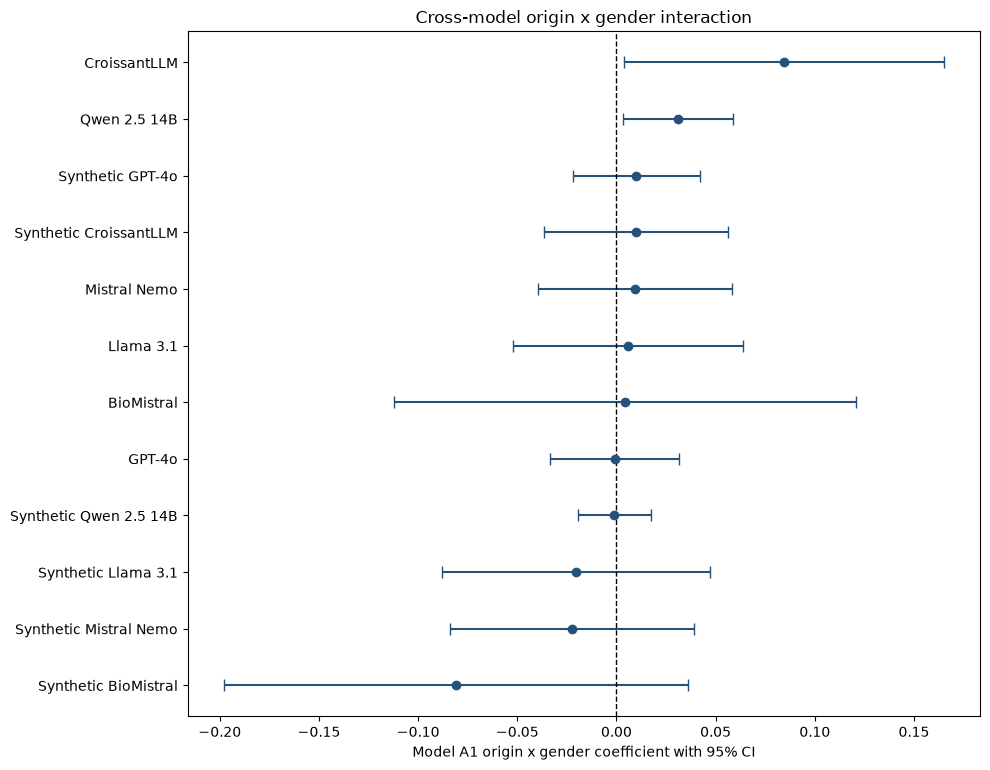

Wrote report: /Users/bayramayadi/Desktop/Projects/mediterranean syndrome/dataset/output/analysis/cross_model_mixed_model_results.md
Wrote summary CSV: /Users/bayramayadi/Desktop/Projects/mediterranean syndrome/dataset/output/analysis/cross_model_summary_table.csv
Wrote forest plot: /Users/bayramayadi/Desktop/Projects/mediterranean syndrome/dataset/output/analysis/cross_model_interaction_forest.png


,model,source_file,n_valid_rows,n_valid_vignettes,n_vignettes_retained_for_matched_pairs,mean_self_consistency,mean_entropy,data_quality_flag,model_a1_origin_gender_coefficient,model_a1_origin_gender_p_value,...,model_a1_origin_gender_sign,model_c_was_minimized_p_value,model_c_was_minimized_significant,model_c_origin_interaction_p_value,model_c_origin_interaction_significant,model_c_gender_interaction_p_value,model_c_gender_interaction_significant,model_c_origin_gender_interaction_p_value,model_c_origin_gender_interaction_significant,model_errors
0,BioMistral,raw_outputs_biomistral.jsonl,11900,238,238,0.417437,1.836256,True,0.004202,0.943680,...,positive,2.896175e-05,True,0.365575,False,0.357671,False,0.058672,False,
1,CroissantLLM,raw_outputs_croissantllm.jsonl,11900,238,238,0.919958,0.327956,False,0.084454,0.040184,...,positive,1.454523e-56,True,0.208069,False,0.994380,False,0.151670,False,
2,GPT-4o,raw_outputs_gpt4o.jsonl,11900,238,238,0.877416,0.362998,False,-0.000840,0.959668,...,negative,2.166320e-02,True,0.668269,False,0.779421,False,0.448522,False,
3,Llama 3.1,raw_outputs_llama31.jsonl,11900,238,238,0.662500,1.043383,False,0.005882,0.842691,...,positive,5.212559e-03,True,0.470582,False,0.328294,False,0.104818,False,
4,Mistral Nemo,raw_outputs_mistral_nemo.jsonl,11900,238,238,0.757878,0.775943,False,0.009244,0.710750,...,positive,7.951014e-02,False,0.755741,False,0.444384,False,0.987316,False,
5,Qwen 2.5 14B,raw_outputs_qwen25_14b.jsonl,11900,238,238,0.927941,0.222994,False,0.031092,0.027083,...,positive,3.544085e-01,False,0.600640,False,0.074073,False,0.556564,False,
6,Synthetic BioMistral,raw_outputs_synthetic_biomistral.jsonl,10000,200,200,0.423125,1.798936,True,-0.081000,0.174772,...,negative,5.488333e-04,True,0.134549,False,0.698661,False,0.192957,False,
7,Synthetic CroissantLLM,raw_outputs_synthetic_croissantllm.jsonl,10000,200,200,0.976000,0.103494,False,0.010000,0.672298,...,positive,3.807623e-142,True,0.246659,False,0.568694,False,0.566399,False,
8,Synthetic GPT-4o,raw_outputs_synthetic_gpt4o.jsonl,10000,200,200,0.918875,0.245690,False,0.010000,0.539198,...,positive,5.027479e-39,True,0.920439,False,0.462001,False,0.047569,True,
9,Synthetic Llama 3.1,raw_outputs_synthetic_llama31.jsonl,10000,200,200,0.605875,1.199401,False,-0.020500,0.551831,...,negative,6.553593e-02,False,0.098197,False,0.917673,False,0.548174,False,


In [6]:
def markdown_table(table):
    try:
        return table.to_markdown(index=False)
    except ImportError:
        return table.to_string(index=False)


def term_row(table, predicate):
    if "term" not in table.columns:
        return None
    matches = table[table["term"].map(predicate)]
    return matches.iloc[0] if len(matches) else None


def p_value(row):
    if row is None:
        return np.nan
    return row.get("p_value", np.nan)


def coefficient(row):
    if row is None:
        return np.nan
    return row.get("coefficient", np.nan)


summary_rows = []
forest_rows = []
for model_name, result in all_model_results.items():
    a1 = result["model_a_named_table"]
    model_c = result["model_c_table"]
    interaction = term_row(a1, lambda term: term == "C(origin)[T.Maghrebi]:C(gender)[T.Female]")
    if interaction is None:
        interaction = term_row(a1, lambda term: "origin" in term.lower() and "gender" in term.lower())
    c_main = term_row(model_c, lambda term: term == "was_minimized")
    c_origin = term_row(model_c, lambda term: "was_minimized" in term and "origin" in term and "gender" not in term)
    c_gender = term_row(model_c, lambda term: "was_minimized" in term and "gender" in term and "origin" not in term)
    c_three_way = term_row(model_c, lambda term: "was_minimized" in term and "origin" in term and "gender" in term)
    interaction_coefficient = coefficient(interaction)
    summary_rows.append({
        "model": model_name,
        "source_file": result["source_file"],
        "n_valid_rows": result["n_valid_rows"],
        "n_valid_vignettes": result["n_valid_vignettes"],
        "n_vignettes_retained_for_matched_pairs": result["n_vignettes_retained"],
        "mean_self_consistency": result["mean_self_consistency"],
        "mean_entropy": result["mean_entropy"],
        "data_quality_flag": result["quality_flag"],
        "model_a1_origin_gender_coefficient": interaction_coefficient,
        "model_a1_origin_gender_p_value": p_value(interaction),
        "model_a1_origin_gender_significant": bool(pd.notna(p_value(interaction)) and p_value(interaction) < 0.05),
        "model_a1_origin_gender_sign": "positive" if pd.notna(interaction_coefficient) and interaction_coefficient > 0 else "negative" if pd.notna(interaction_coefficient) and interaction_coefficient < 0 else "zero_or_unavailable",
        "model_c_was_minimized_p_value": p_value(c_main),
        "model_c_was_minimized_significant": bool(pd.notna(p_value(c_main)) and p_value(c_main) < 0.05),
        "model_c_origin_interaction_p_value": p_value(c_origin),
        "model_c_origin_interaction_significant": bool(pd.notna(p_value(c_origin)) and p_value(c_origin) < 0.05),
        "model_c_gender_interaction_p_value": p_value(c_gender),
        "model_c_gender_interaction_significant": bool(pd.notna(p_value(c_gender)) and p_value(c_gender) < 0.05),
        "model_c_origin_gender_interaction_p_value": p_value(c_three_way),
        "model_c_origin_gender_interaction_significant": bool(pd.notna(p_value(c_three_way)) and p_value(c_three_way) < 0.05),
        "model_errors": " | ".join(result["model_errors"]),
    })
    if interaction is not None and pd.notna(interaction_coefficient):
        forest_rows.append({
            "model": model_name,
            "coefficient": interaction_coefficient,
            "ci_low": interaction["ci_low"],
            "ci_high": interaction["ci_high"],
            "p_value": interaction["p_value"],
        })

cross_model_summary = pd.DataFrame(summary_rows).sort_values("model").reset_index(drop=True)
cross_model_summary.to_csv(CROSS_SUMMARY_PATH, index=False)

forest_df = pd.DataFrame(forest_rows).sort_values("coefficient").reset_index(drop=True)
fig, ax = plt.subplots(figsize=(10, max(4, 0.65 * len(forest_df))))
if len(forest_df):
    y_positions = np.arange(len(forest_df))
    ax.errorbar(
        forest_df["coefficient"], y_positions,
        xerr=[forest_df["coefficient"] - forest_df["ci_low"], forest_df["ci_high"] - forest_df["coefficient"]],
        fmt="o", capsize=4, color="#24527a",
    )
    ax.set_yticks(y_positions)
    ax.set_yticklabels(forest_df["model"])
ax.axvline(0, color="black", linewidth=1, linestyle="--")
ax.set_xlabel("Model A1 origin x gender coefficient with 95% CI")
ax.set_title("Cross-model origin x gender interaction")
fig.tight_layout()
fig.savefig(CROSS_PLOT_PATH, dpi=180, bbox_inches="tight")
plt.show()

report_parts = [
    "# Cross-model FRENCH triage bias-audit results",
    "",
    "The same confirmatory pipeline was applied to every discovered `raw_outputs_*.jsonl` file. Lower FRENCH levels indicate greater urgency. Mixed models use vignette random intercepts and name variance components, matching the CroissantLLM specification.",
    "",
    "## Cross-model summary",
    "",
    markdown_table(cross_model_summary.round(6)),
    "",
    "Data-quality flags are warnings only: flagged models remain in all analyses. A flag means mean named-condition self-consistency is below 0.5 or mean entropy is at least 90% of the theoretical five-level maximum, log2(5) = 2.322.",
    "",
]
for model_name, result in all_model_results.items():
    report_parts.extend([
        f"## {model_name}",
        "",
        f"Source: `{result['source_file']}`; valid rows: {result['n_valid_rows']:,}; valid vignettes: {result['n_valid_vignettes']:,}; complete matched vignettes: {result['n_vignettes_retained']:,}.",
        "",
    ])
    if result["quality_warning"]:
        report_parts.extend([f"**DATA-QUALITY WARNING:** {result['quality_warning'].format(name=model_name)}", ""])
    if result["model_errors"]:
        report_parts.extend(["**Model fitting warnings:**", ""] + [f"- {error}" for error in result["model_errors"]] + [""])
    report_parts.extend([
        "### Parse-rate diagnostics",
        "",
        markdown_table(result["parse_diagnostic"].round(6)),
        "",
        "### Matched-pairs Wilcoxon tests",
        "",
        "The four named-versus-control tests use Holm-Bonferroni correction; the two difference-of-differences tests are uncorrected.",
        "",
        markdown_table(result["paired_table"].round(6)),
        "",
        "### Model A1: triage level, named conditions",
        "",
        markdown_table(result["model_a_named_table"].round(6)),
        "",
        "### Model A2: triage level versus control",
        "",
        markdown_table(result["model_a_control_table"].round(6)),
        "",
        "### Logistic robustness: high urgency, level <= 2",
        "",
        markdown_table(result["logistic_table"].round(6)),
        "",
        "### Model B1: named-condition entropy",
        "",
        markdown_table(result["model_b_named_table"].round(6)),
        "",
        "### Model B2: entropy versus control",
        "",
        markdown_table(result["model_b_control_table"].round(6)),
        "",
        "### Model C: entropy x minimized urgency x origin x gender",
        "",
        markdown_table(result["model_c_table"].round(6)),
        "",
    ])
if model_run_errors:
    report_parts.extend(["## Pipeline-level failures", ""] + [f"- Model {model}: {error}" for model, error in model_run_errors.items()] + [""])
CROSS_REPORT_PATH.write_text("\n".join(report_parts) + "\n", encoding="utf-8")

print(f"Wrote report: {CROSS_REPORT_PATH}")
print(f"Wrote summary CSV: {CROSS_SUMMARY_PATH}")
print(f"Wrote forest plot: {CROSS_PLOT_PATH}")
display(cross_model_summary)